# Preset and definition of variables
Importação de bibliotecas base, configuração do ambiente visual e definição de variáveis globais e caminhos para a validação *single-subject*.

In [1]:
import os
import zipfile
import mne
import mne_nirs
import mne_nirs.io
from mne_nirs.channels import get_long_channels, get_short_channels, picks_pair_to_idx
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from nilearn.glm.first_level import make_first_level_design_matrix

# Definição de Variáveis Globais (Single-Subject) com Caminho Absoluto
BASE_DIR = r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
SUJEITO = "sub-001"
RUN = "sub-001_ses-01_tk-dm_run-1_nirs_001"
SNIRF_FILE = "2026-08-04_002.snirf"
ZIP_FILE = "2026-08-04_002.zip"

pasta_alvo = os.path.join(BASE_DIR, SUJEITO, "nirs", RUN)
caminho_snirf = os.path.join(pasta_alvo, SNIRF_FILE)
caminho_zip = os.path.join(pasta_alvo, ZIP_FILE)
pasta_extraida_wings = os.path.join(pasta_alvo, "dados_wings_extraidos")

# 1. Carregamento de Dados e Inspeção Inicial (Raw Signal)
Extração dos dados periféricos WINGS (SPA-fNIRS), leitura do ficheiro `.snirf` e renderização estática (`Agg`) da montagem da touca e da densidade ótica bruta para garantir a estabilidade do Kernel.

A ler o ficheiro fNIRS:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\2026-08-04_002.snirf

Duração da Gravação: 424.87 segundos
Frequência de Amostragem (Hz): 10.17
Triggers encontrados: ['100', '110', '120', '130', '150', '160']

A desenhar topologia da touca 2D...
Using matplotlib as 2D backend.


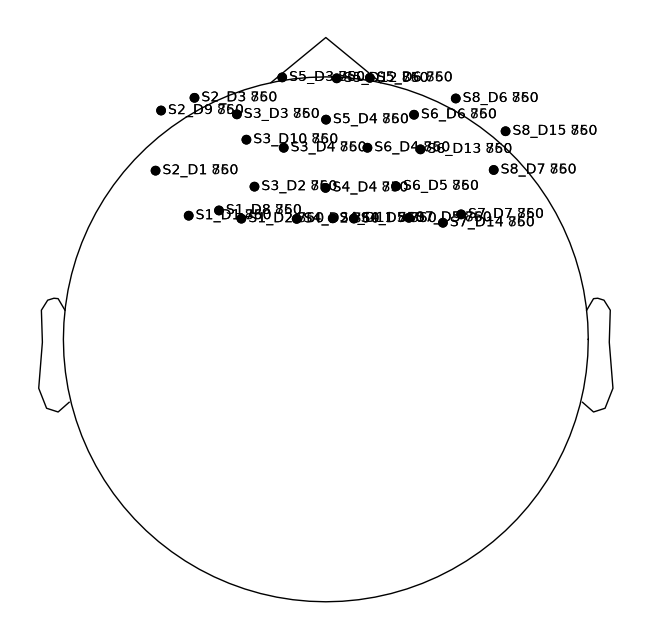

A processar Densidade Ótica (OD)...


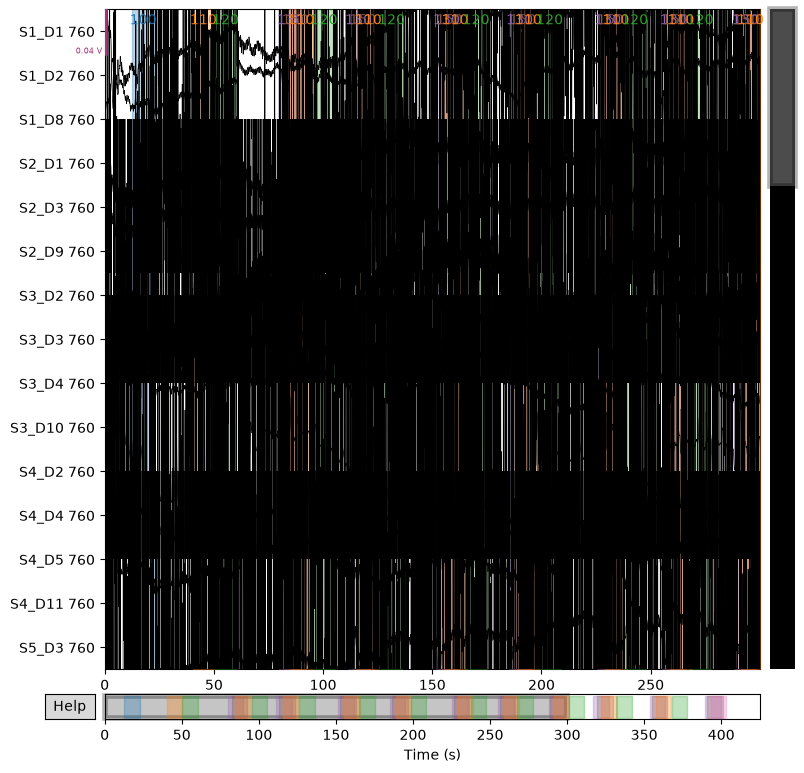


Processamento visual concluído com sucesso!


In [2]:
import os
import zipfile
import mne
import mne_nirs
import matplotlib.pyplot as plt

# 1.1 Extrair dados WINGS se necessário
if os.path.exists(caminho_zip) and not os.path.exists(pasta_extraida_wings):
    print("A extrair dados do WINGS (SPA-fNIRS)...")
    with zipfile.ZipFile(caminho_zip, 'r') as zip_ref:
        zip_ref.extractall(pasta_extraida_wings)
    print("Extração do WINGS concluída!")

# 1.2 Carregar o sinal fNIRS bruto
print(f"A ler o ficheiro fNIRS:\n{caminho_snirf}")
raw = mne.io.read_raw_snirf(caminho_snirf, preload=True, verbose=False)

# 1.3 Inspecionar a estrutura do ficheiro
print("\n" + "="*50)
print(f"Duração da Gravação: {raw.times[-1]:.2f} segundos")
print(f"Frequência de Amostragem (Hz): {raw.info['sfreq']:.2f}")
triggers = sorted(set([str(t) for t in raw.annotations.description]))
print(f"Triggers encontrados: {triggers}")
print("="*50)

# 1.4 Visualizar a Montagem da Touca (Optódes) em 2D
print("\nA desenhar topologia da touca 2D...")
mne.viz.set_browser_backend('matplotlib') 
fig_montagem_2d = raw.plot_sensors(show_names=True)
plt.show() # Usa plt.show() em vez de fig.show()

# 1.5 Converter para Densidade Ótica (OD) e mostrar o sinal
print("A processar Densidade Ótica (OD)...")
raw_od = mne.preprocessing.nirs.optical_density(raw)

# Desenhar a OD (apenas os primeiros 15 canais)
fig_od = raw_od.plot(
    n_channels=15, 
    duration=300
)
plt.show() # Usa plt.show() em vez de fig.show()

print("\nProcessamento visual concluído com sucesso!")

# 1.6 Controlo de Qualidade do Sinal: Scalp Coupling Index (SCI)
Cálculo do índice de acoplamento (SCI) para avaliar o contacto ótimo entre optódes e escalpe. Exclusão automática de canais com sinal de baixa qualidade (SCI < 0.7).

A calcular o Scalp Coupling Index (SCI)...


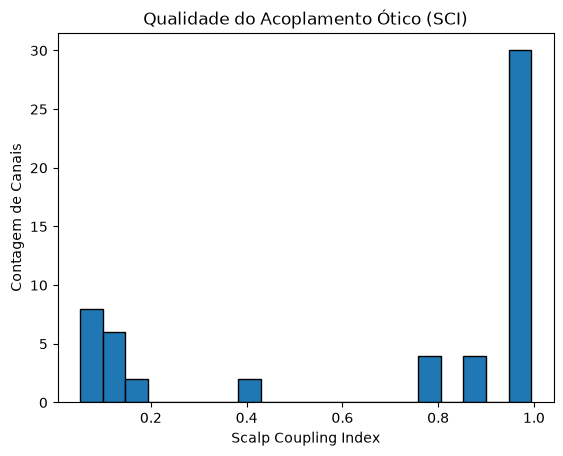


Canais marcados como maus (SCI < 0.7): 18
['S1_D8 760', 'S2_D9 760', 'S3_D2 760', 'S3_D10 760', 'S4_D11 760', 'S5_D12 760', 'S6_D13 760', 'S7_D14 760', 'S8_D15 760', 'S1_D8 850', 'S2_D9 850', 'S3_D2 850', 'S3_D10 850', 'S4_D11 850', 'S5_D12 850', 'S6_D13 850', 'S7_D14 850', 'S8_D15 850']


In [3]:
# Calcular o Scalp Coupling Index (SCI)
print("A calcular o Scalp Coupling Index (SCI)...")
sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od)

# Desenhar Histograma do SCI
fig_sci, ax = plt.subplots()
ax.hist(sci, bins=20, edgecolor='black')
ax.set(xlabel='Scalp Coupling Index', ylabel='Contagem de Canais', title='Qualidade do Acoplamento Ótico (SCI)')
plt.show()

# Marcar os canais com SCI < 0.7 como "Bads" para que as funções seguintes os ignorem
LIMIAR_SCI = 0.7
bads_sci = list(np.array(raw_od.ch_names)[sci < LIMIAR_SCI])
raw_od.info['bads'] = bads_sci

print(f"\nCanais marcados como maus (SCI < {LIMIAR_SCI}): {len(bads_sci)}")
if len(bads_sci) > 0:
    print(bads_sci)

# 2. Limpeza do Sinal: Correção de Movimento (TDDR) e Ruído Sistémico (SSR)
Aplicação do algoritmo *Temporal Derivative Distribution Repair* (TDDR) para correção robusta de picos/desvios abruptos, seguida da Regressão de Canais Curtos (SSR) para atenuar o ruído da fisiologia sistémica (fluxo sanguíneo no couro cabeludo).

A aplicar TDDR (Correção de Movimento)...


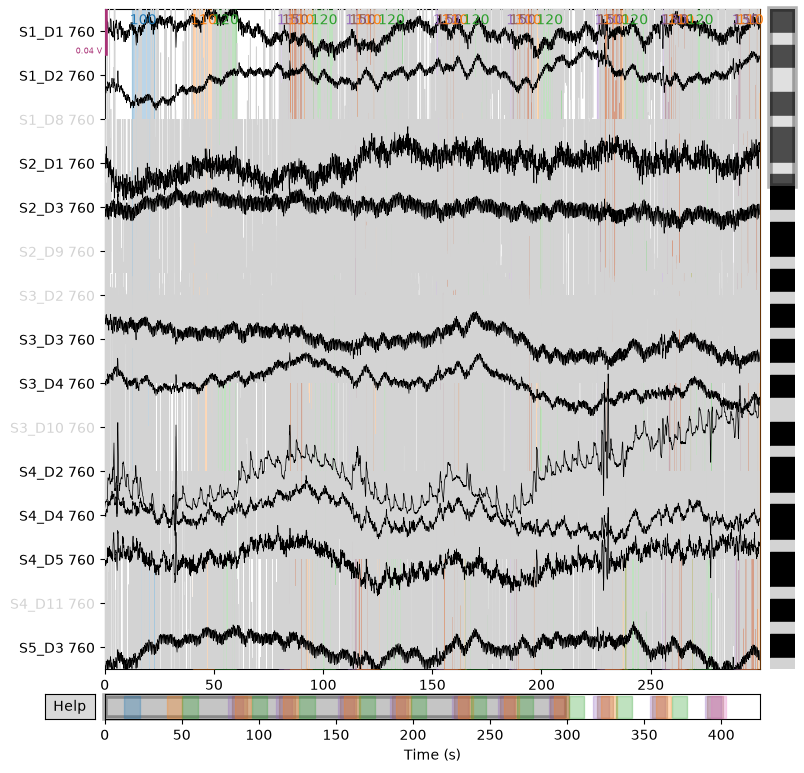


A verificar viabilidade da Regressão de Canais Curtos (SSR)...
AVISO: Nenhum canal curto com qualidade (SCI >= 0.7) sobreviveu.
A saltar o SSR. O processamento seguirá de forma robusta apenas com TDDR e Filtro.


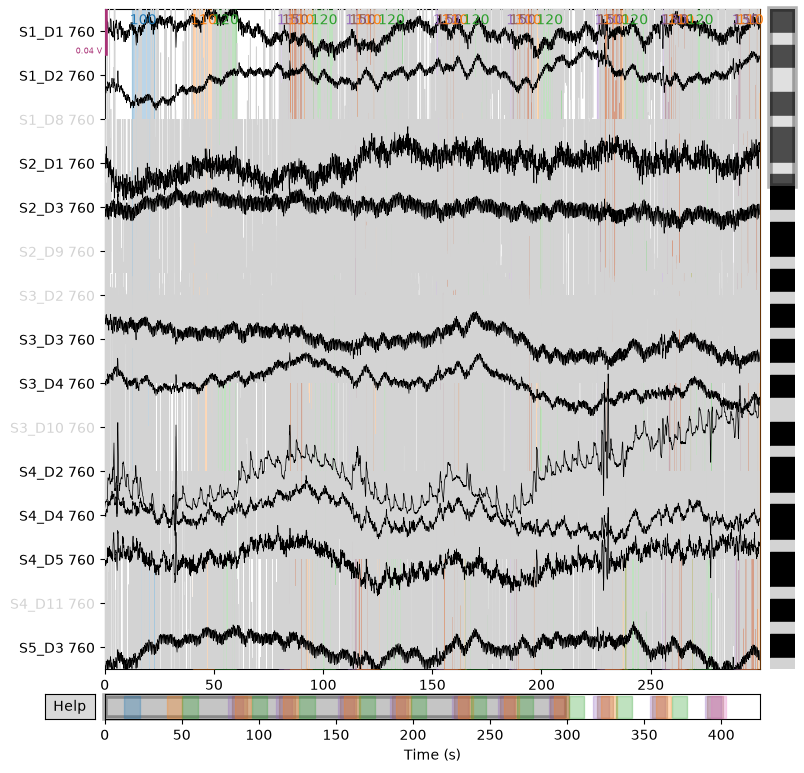


Bloco de limpeza de artefactos concluído!


In [4]:
# 2.1 Correção de Movimento (TDDR)
print("A aplicar TDDR (Correção de Movimento)...")
raw_od_tddr = mne.preprocessing.nirs.temporal_derivative_distribution_repair(raw_od)

# Desenhar o sinal após o TDDR (apenas os primeiros 15 canais)
fig_tddr = raw_od_tddr.plot(n_channels=15, duration=300)
plt.show()

# 2.2 Regressão de Canais Curtos (SSR) Dinâmica
print("\nA verificar viabilidade da Regressão de Canais Curtos (SSR)...")

# Identificar canais que sobreviveram ao SCI e medir a sua distância
picks_validos = mne.pick_types(raw_od_tddr.info, fnirs=True, exclude='bads')
distancias = mne.preprocessing.nirs.source_detector_distances(raw_od_tddr.info, picks=picks_validos)

# Contar quantos canais curtos (<= 1.0 cm ou 0.01 m) sobreviveram
num_curtos_validos = np.sum(distancias <= 0.01)

if num_curtos_validos > 0:
    print(f"Encontrados {num_curtos_validos} canais curtos válidos. A aplicar SSR...")
    raw_od_ssr = mne_nirs.signal_enhancement.short_channel_regression(raw_od_tddr)
else:
    print("AVISO: Nenhum canal curto com qualidade (SCI >= 0.7) sobreviveu.")
    print("A saltar o SSR. O processamento seguirá de forma robusta apenas com TDDR e Filtro.")
    raw_od_ssr = raw_od_tddr.copy() # O sinal passa para a fase seguinte sem a regressão curta

# Desenhar o sinal final desta etapa (apenas os primeiros 15 canais)
fig_ssr = raw_od_ssr.plot(n_channels=15, duration=300)
plt.show()

print("\nBloco de limpeza de artefactos concluído!")

# 3. Conversão para Hemoglobina (mBLL) e Filtragem Temporal
Transformação da Densidade Ótica em concentrações de Oxiemoglobina (HbO) e Desoxiemoglobina (HbR) usando a Lei de Beer-Lambert Modificada (ppf=0.1). Aplicação de filtro passa-banda (0.01 Hz a 0.10 Hz) para isolar as frequências de interesse hemodinâmico.

A converter para HbO e HbR (mBLL)...
A aplicar filtro passa-banda (0.01 - 0.5 Hz)...


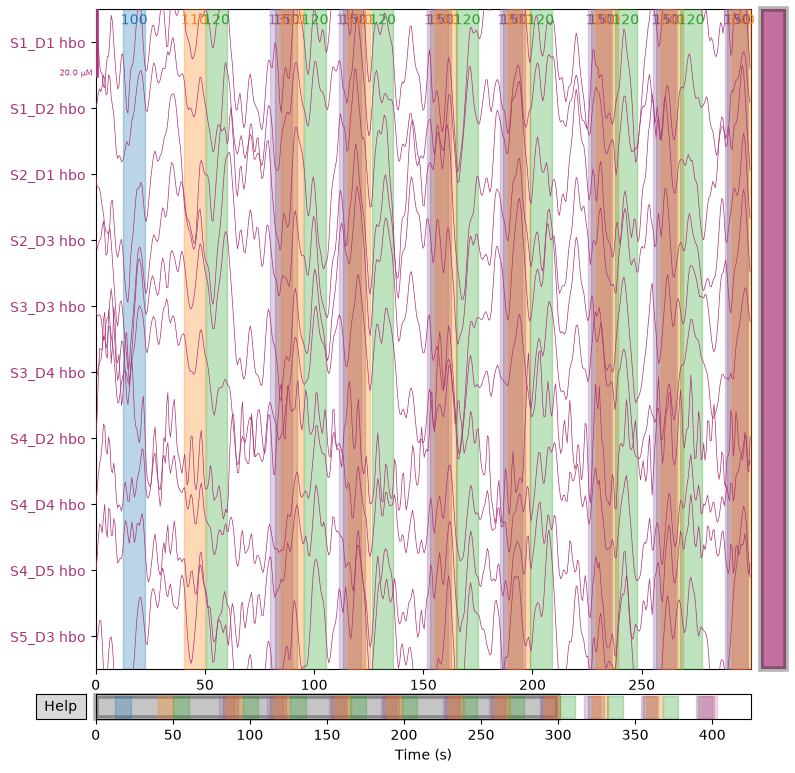


Conversão e Filtragem concluídas com sucesso!


In [5]:
# Definir parâmetros baseados no teu relatório metodológico
PPF = 0.1
LOW_CUTOFF_HZ = 0.01
HIGH_CUTOFF_HZ = 0.5

# 3.1 Lei de Beer-Lambert Modificada (mBLL)
print("A converter para HbO e HbR (mBLL)...")
raw_haemo = mne.preprocessing.nirs.beer_lambert_law(
    raw_od_ssr,
    ppf=PPF,
)

# 3.2 Filtragem Temporal (IIR)
print(f"A aplicar filtro passa-banda ({LOW_CUTOFF_HZ} - {HIGH_CUTOFF_HZ} Hz)...")
raw_filtrado = raw_haemo.filter(
    l_freq=LOW_CUTOFF_HZ,
    h_freq=HIGH_CUTOFF_HZ,
    method="iir",
    verbose=False,
)

# Desenhar o sinal final de HbO e HbR após a filtragem
# Vamos usar o pick_types para selecionar apenas alguns canais de HbO para visualização limpa
picks_hbo = mne.pick_types(raw_filtrado.info, fnirs='hbo')
fig_haemo = raw_filtrado.plot(
    picks=picks_hbo[:10], # Mostra os primeiros 10 canais de HbO
    duration=300
)
plt.show()

print("\nConversão e Filtragem concluídas com sucesso!")

# 3.3 Segmentação por Épocas (Epoching) e Visualização de ERPs
Extração de segmentos de sinal (Épocas) centrados nos marcadores de estímulo ('Video'). Alinhamento das tentativas para desenhar a curva média de resposta hemodinâmica (ERPs) com intervalo de confiança.

A construir as Épocas para o estímulo 'Video'...

Visualização das ondas Evoked (HbO) para os primeiros 4 canais cerebrais:


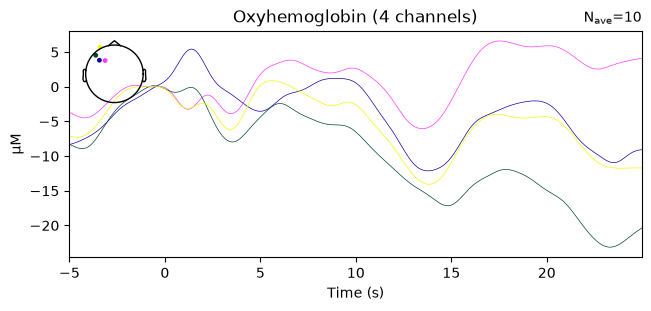


Curva Média com Intervalo de Confiança (Canal S1_D1 hbo):


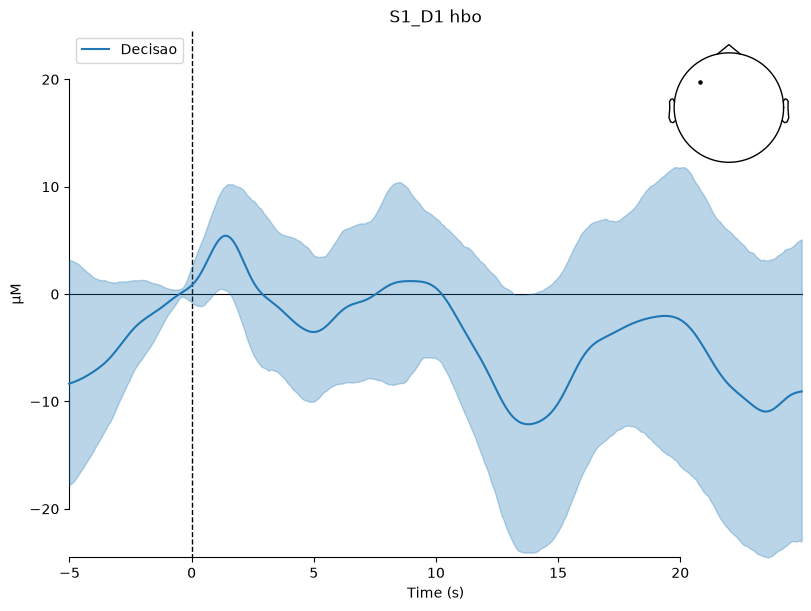

In [8]:
# 1. Renomear marcadores para o Epoching perceber (podes apagar o código igual que tinhas no bloco do GLM)
EVENTOS_DM = {
    "100": "BaselineInic", "110": "Jitter", "120": "Video", "130": "Decisao",
    "140": "RespA", "141": "RespB", "142": "RespC", "143": "RespD",
    "150": "FixPost", "160": "BaselineFin"
}
renomear = {cod: nome for cod, nome in EVENTOS_DM.items() if cod in raw_filtrado.annotations.description}
raw_filtrado.annotations.rename(renomear)

# Extrair os eventos
events, event_dict = mne.events_from_annotations(raw_filtrado, verbose=False)

# Definir janela de 5s antes do estímulo até 25s depois
tmin, tmax = -5.0, 25.0

print("A construir as Épocas para o estímulo 'Video'...")
epochs = mne.Epochs(
    raw_filtrado,
    events,
    event_id=event_dict,
    tmin=tmin,
    tmax=tmax,
    baseline=(-1.0, 0.0), # Subtrai a média da baseline (1s anteriores) à curva
    preload=True,
    verbose=False
)
task='Decisao'
if task in epochs.event_id:
    # 1. Desenhar a média (Evoked) das concentrações (ex: 4 primeiros canais de HbO)
    evoked_task = epochs[task].average()
    picks_hbo = mne.pick_types(evoked_task.info, fnirs='hbo', exclude='bads')
    
    print("\nVisualização das ondas Evoked (HbO) para os primeiros 4 canais cerebrais:")
    fig_evoked = evoked_task.plot(picks=picks_hbo[:4])
    plt.show()

    # 2. Desenhar o Gráfico com Intervalo de Confiança (95%) para 1 Canal Específico
    canal_alvo = raw_filtrado.ch_names[picks_hbo[0]] # Seleciona o 1º canal válido
    
    # Truque do orientador para forçar o cálculo da variância: listar tentativas individuais
    task_epochs = epochs[task]
    evokeds_list = [task_epochs[i].average() for i in range(len(task_epochs))]
    
    print(f"\nCurva Média com Intervalo de Confiança (Canal {canal_alvo}):")
    fig_compare = mne.viz.plot_compare_evokeds(
        {task: evokeds_list},
        picks=[canal_alvo],
        ci=True, # Mostra a mancha do erro padrão/variância
        show_sensors='upper right'
    )
    plt.show()
else:
    print("Atenção: Marcador não encontrado para criar épocas.")

# 4. Isolamento Cortical, Renomeação de Triggers e GLM
Exclusão de canais curtos para reter apenas os canais corticais longos. Renomeação dos marcadores do paradigma de *Decision Making* e aplicação do Modelo Linear Geral (GLM) de 1º nível.

In [8]:
# 4.1 Isolamento Cortical (manter apenas canais fNIRS longos e válidos)
print("A extrair canais corticais longos...")
picks_fnirs = mne.pick_types(raw_filtrado.info, fnirs=True, exclude="bads")

# Calcular distâncias para garantir que os canais têm pelo menos 1.5 cm
distancias = mne.preprocessing.nirs.source_detector_distances(raw_filtrado.info, picks=picks_fnirs)
DISTANCIA_MIN_LONGA_M = 0.015
picks_longos = picks_fnirs[distancias > DISTANCIA_MIN_LONGA_M]

raw_cerebral = raw_filtrado.copy().pick(picks_longos)
print(f"Canais longos corticais mantidos: {len(picks_longos)}")

# 4.2 Renomear Triggers (Decision Making)
EVENTOS_DM = {
    "100": "BaselineInic",
    "110": "Jitter",
    "120": "Video",
    "130": "Decisao",
    "140": "RespA",
    "141": "RespB",
    "142": "RespC",
    "143": "RespD",
    "150": "FixPost",
    "160": "BaselineFin",
}

print("\nA renomear marcadores...")
renomear = {
    codigo: nome
    for codigo, nome in EVENTOS_DM.items()
    if codigo in raw_cerebral.annotations.description
}
raw_cerebral.annotations.rename(renomear)
print(f"Marcadores renomeados: {set(raw_cerebral.annotations.description)}")

# 4.3 Modelo Linear Geral (GLM)
print("\nA construir a matriz de desenho e a correr o GLM...")
# IMPORTAÇÃO CORRIGIDA PARA MNE_NIRS
from mne_nirs.experimental_design import make_first_level_design_matrix 
from mne_nirs.statistics import run_glm

# Criar a matriz de desenho do 1º nível (GLM)
design_matrix = make_first_level_design_matrix(
    raw_cerebral,
    drift_model="cosine",
    high_pass=LOW_CUTOFF_HZ,
    hrf_model="glover",
)

# Executar o GLM
glm_est = run_glm(raw_cerebral, design_matrix)

# Calcular o contraste: Vídeo vs. Baseline Implícito
colunas = design_matrix.columns.tolist()
vetor_contraste = np.zeros(len(colunas))

if "Video" in colunas:
    vetor_contraste[colunas.index("Video")] = 1
    contraste = glm_est.compute_contrast(vetor_contraste)
    
    # Converter resultados num DataFrame pandas para visualizar
    df_contraste = contraste.to_dataframe()
    
    print("\nResultados do GLM (Primeiros 10 canais corticais para 'Video'):")
    display(df_contraste.head(10))
else:
    print("\nAtenção: O marcador 'Video' não foi encontrado na matriz de desenho.")

A extrair canais corticais longos...
Canais longos corticais mantidos: 38

A renomear marcadores...
Marcadores renomeados: {'Jitter', 'BaselineInic', 'Decisao', 'FixPost', 'BaselineFin', 'Video'}

A construir a matriz de desenho e a correr o GLM...

Resultados do GLM (Primeiros 10 canais corticais para 'Video'):


variable,ContrastType,effect,p_value,stat,z_score,Source,Detector,Chroma,Significant,ch_name
0,t,0.000018,3.300978e-35,12.435713,12.325516,1,1,hbo,True,S1_D1 hbo
2,t,0.000014,1.299432e-55,15.892338,15.665619,1,2,hbo,True,S1_D2 hbo
4,t,0.000007,5.296459e-06,4.409923,4.404702,2,1,hbo,True,S2_D1 hbo
6,t,0.000017,2.729845e-38,13.011026,12.885111,2,3,hbo,True,S2_D3 hbo
8,t,0.000028,2.583457e-74,18.556559,18.199935,3,3,hbo,True,S3_D3 hbo
10,t,0.000027,3.789215e-118,23.812215,23.078699,3,4,hbo,True,S3_D4 hbo
12,t,0.000006,1.556250e-06,4.669415,4.663253,4,2,hbo,True,S4_D2 hbo
14,t,0.000017,3.552582e-78,19.066636,18.680722,4,4,hbo,True,S4_D4 hbo
16,t,0.000014,2.136709e-39,13.211925,13.080195,4,5,hbo,True,S4_D5 hbo
18,t,0.000039,1.464587e-164,28.541601,27.313540,5,3,hbo,True,S5_D3 hbo


# 5. Exportação de Dados Processados (Derivatives)
Gravação do sinal fNIRS longo e limpo, bem como da matriz de resultados estatísticos do Modelo Linear Geral (GLM) em formato CSV, cumprindo as normas de estruturação BIDS para análises multi-sujeito.

In [10]:
print("A guardar os dados de validação single-subject...")

# Cria a pasta de Derivatives dentro da pasta alvo do teu projeto
pasta_derivatives = os.path.join(BASE_DIR, "derivatives", "mne-nirs", SUJEITO)
os.makedirs(pasta_derivatives, exist_ok=True)

# 1. Guardar a tabela CSV com os contrastes do GLM
if 'df_contraste' in locals():
    caminho_csv = os.path.join(pasta_derivatives, f"{SUJEITO}_{RUN}_glm_stats.csv")
    df_contraste.to_csv(caminho_csv, index=False)
    print(f"Resultados estatísticos do GLM guardados em:\n{caminho_csv}")

# 2. Guardar o sinal fNIRS limpo e cerebral (apenas canais longos retidos na var `raw_cerebral`)
# A extensão oficial exigida pelo MNE para gravação raw é _raw.fif
caminho_fif = os.path.join(pasta_derivatives, f"{SUJEITO}_{RUN}_long_haemo_raw.fif")
raw_cerebral.save(caminho_fif, overwrite=True)
print(f"\nSinal hemodinâmico limpo guardado em:\n{caminho_fif}")

print("\n--- Validação Single-Subject concluída e dados arquivados com sucesso! ---")

A guardar os dados de validação single-subject...
Resultados estatísticos do GLM guardados em:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\derivatives\mne-nirs\sub-001\sub-001_sub-001_ses-01_tk-dm_run-1_nirs_001_glm_stats.csv
Overwriting existing file.
Writing C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\derivatives\mne-nirs\sub-001\sub-001_sub-001_ses-01_tk-dm_run-1_nirs_001_long_haemo_raw.fif
Overwriting existing file.
Closing C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\derivatives\mne-nirs\sub-001\sub-001_sub-001_ses-01_tk-dm_run-1_nirs_001_long_haemo_raw.fif
[done]

Sinal hemodinâmico limpo guardado em:
C:\Users\guilh\Desktop\OneDrive - Univers

In [2]:
# ============================================================
# 1. CONFIGURAÇÃO — VALIDAÇÃO SINGLE-SUBJECT
# ============================================================

from pathlib import Path
import json
import platform

import mne
import mne_nirs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1.1 Identificação da gravação
# ------------------------------------------------------------

BASE_DIR = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

SUJEITO = "sub-001"
SESSAO = "ses-01"
TAREFA = "dm"
NUM_RUN = 1

ID_GRAVACAO = (
    f"{SUJEITO}_{SESSAO}_tk-{TAREFA}_run-{NUM_RUN}_nirs_001"
)


# ------------------------------------------------------------
# 1.2 Pastas de entrada
# ------------------------------------------------------------

PASTA_SUJEITO = BASE_DIR / SUJEITO

PASTA_RUN = (
    PASTA_SUJEITO
    / "nirs"
    / ID_GRAVACAO
)

if not PASTA_RUN.is_dir():
    raise FileNotFoundError(
        f"A pasta da gravação não foi encontrada:\n{PASTA_RUN}"
    )


# ------------------------------------------------------------
# 1.3 Ficheiro SNIRF com nome normalizado
# O nome do ficheiro deve coincidir com o nome da pasta da run.
# ------------------------------------------------------------

CAMINHO_SNIRF = PASTA_RUN / f"{ID_GRAVACAO}.snirf"

if not CAMINHO_SNIRF.is_file():
    raise FileNotFoundError(
        "O ficheiro SNIRF esperado não foi encontrado.\n"
        "Confirma se o nome do ficheiro coincide com o nome "
        f"da pasta da gravação:\n{CAMINHO_SNIRF}"
    )


# ------------------------------------------------------------
# 1.4 Pasta de saída por participante e gravação
# ------------------------------------------------------------

PASTA_DERIVATIVES = (
    PASTA_SUJEITO
    / "fNIRS_epochs_derivatives"
    / ID_GRAVACAO
)

PASTA_DERIVATIVES.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1.5 Mapa dos eventos
# Define nomes; ainda não altera as anotações do sinal.
# ------------------------------------------------------------

EVENTOS_DM = {
    "100": "BaselineInic",
    "110": "Jitter",
    "120": "Video",
    "130": "Decisao",
    "140": "RespA",
    "141": "RespB",
    "142": "RespC",
    "143": "RespD",
    "150": "FixPost",
    "160": "BaselineFin",
}


# ------------------------------------------------------------
# 1.6 Informação do protocolo para auditoria posterior
# Durações nominais dos clips, em segundos.
# Não representam a ordem efetiva de apresentação.
# ------------------------------------------------------------

DURACOES_NOMINAIS_VIDEO_S = {
    1: {
        1: 17,
        2: 22,
        3: 19,
        4: 13,
        5: 13,
        6: 17,
        7: 15,
        8: 19,
        9: 24,
        10: 27,
    },
    2: {
        11: 17,
        12: 21,
        13: 17,
        14: 20,
        15: 14,
        16: 18,
        17: 20,
        18: 21,
        19: 20,
        20: 18,
    },
}

N_ENSAIOS_ESPERADOS = 10
DURACAO_MAX_RESPOSTA_S = 2.5


# ------------------------------------------------------------
# 1.7 Identificação das versões
# ------------------------------------------------------------

VERSOES = {
    "python": platform.python_version(),
    "mne": mne.__version__,
    "mne_nirs": getattr(mne_nirs, "__version__", "não identificada"),
    "numpy": np.__version__,
    "pandas": pd.__version__,
}


# ------------------------------------------------------------
# 1.8 Resumo da configuração
# ------------------------------------------------------------

print("=" * 70)
print("CONFIGURAÇÃO SINGLE-SUBJECT")
print("=" * 70)

print(f"Participante: {SUJEITO}")
print(f"Sessão:       {SESSAO}")
print(f"Tarefa:       {TAREFA}")
print(f"Run:          {NUM_RUN}")

print(f"\nIdentificador da gravação:\n{ID_GRAVACAO}")

print(f"\nSNIRF selecionado:\n{CAMINHO_SNIRF}")

print(f"\nPasta de saída:\n{PASTA_DERIVATIVES}")

print(f"\nNúmero de ensaios esperado: {N_ENSAIOS_ESPERADOS}")
print(
    "Duração máxima da janela de resposta: "
    f"{DURACAO_MAX_RESPOSTA_S:.1f} s"
)

print("\nVersões:")
for biblioteca, versao in VERSOES.items():
    print(f"  {biblioteca}: {versao}")

print("\nConfiguração concluída. O sinal ainda não foi carregado.")
print("=" * 70)

CONFIGURAÇÃO SINGLE-SUBJECT
Participante: sub-001
Sessão:       ses-01
Tarefa:       dm
Run:          1

Identificador da gravação:
sub-001_ses-01_tk-dm_run-1_nirs_001

SNIRF selecionado:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001.snirf

Pasta de saída:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\sub-001_ses-01_tk-dm_run-1_nirs_001

Número de ensaios esperado: 10
Duração máxima da janela de resposta: 2.5 s

Versões:
  python: 3.12.16
  mne: 1.12.1
  mne_nirs: 0.7.3
  numpy: 1.26.4
  pandas: 3.0.6

Configuração concluída. O sinal ainda não foi carregado.


A carregar o ficheiro SNIRF:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001.snirf

ESTRUTURA DA GRAVAÇÃO
Identificador: sub-001_ses-01_tk-dm_run-1_nirs_001
Última amostra em: 424.87 s
Frequência de amostragem: 10.1725 Hz
Número de amostras: 4323
Número de séries de medição: 56

Tipos de canal:
tipo
fnirs_cw_amplitude    56

Canais inicialmente marcados como maus: []

Primeiros canais:
 indice      canal               tipo  marcado_mau
      0  S1_D1 760 fnirs_cw_amplitude        False
      1  S1_D2 760 fnirs_cw_amplitude        False
      2  S1_D8 760 fnirs_cw_amplitude        False
      3  S2_D1 760 fnirs_cw_amplitude        False
      4  S2_D3 760 fnirs_cw_amplitude        False
      5  S2_D9 760 fnirs_cw_amplitude        False
      6  S3_D2 760 fnirs_cw_amplitude        False
      7

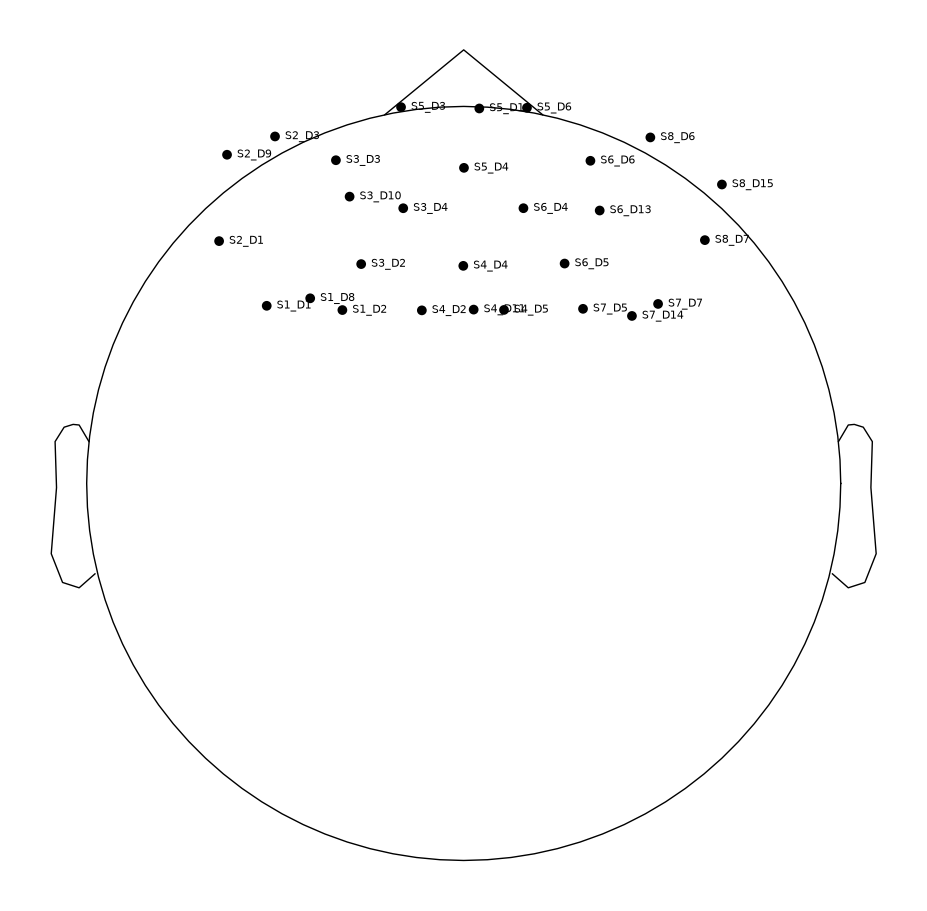


Ficheiros de inspeção guardados:
  sub-001_ses-01_tk-dm_run-1_nirs_001_raw_channels.csv
  sub-001_ses-01_tk-dm_run-1_nirs_001_raw_annotations.csv
  sub-001_ses-01_tk-dm_run-1_nirs_001_raw_event_counts.csv
  sub-001_ses-01_tk-dm_run-1_nirs_001_sensor_layout.png

Leitura e inspeção inicial concluídas.
O objeto 'raw' mantém todos os canais e anotações originais.
Ainda não foi calculada a densidade ótica.


In [3]:
# ============================================================
# 2. LEITURA DO SNIRF E INSPEÇÃO INICIAL
# ============================================================

# ------------------------------------------------------------
# 2.1 Carregar o sinal bruto
# ------------------------------------------------------------

print(f"A carregar o ficheiro SNIRF:\n{CAMINHO_SNIRF}")

raw = mne.io.read_raw_snirf(
    CAMINHO_SNIRF,
    preload=True,
    verbose=False,
)


# ------------------------------------------------------------
# 2.2 Inspecionar a estrutura da gravação
# ------------------------------------------------------------

tipos_canal = raw.get_channel_types()

df_canais = pd.DataFrame({
    "indice": np.arange(len(raw.ch_names)),
    "canal": raw.ch_names,
    "tipo": tipos_canal,
    "marcado_mau": [
        nome in raw.info["bads"]
        for nome in raw.ch_names
    ],
})

print("\n" + "=" * 70)
print("ESTRUTURA DA GRAVAÇÃO")
print("=" * 70)

print(f"Identificador: {ID_GRAVACAO}")
print(f"Última amostra em: {raw.times[-1]:.2f} s")
print(f"Frequência de amostragem: {raw.info['sfreq']:.4f} Hz")
print(f"Número de amostras: {raw.n_times}")
print(f"Número de séries de medição: {len(raw.ch_names)}")

print("\nTipos de canal:")
print(df_canais["tipo"].value_counts().to_string())

print(f"\nCanais inicialmente marcados como maus: {raw.info['bads']}")

print("\nPrimeiros canais:")
print(df_canais.head(12).to_string(index=False))


# ------------------------------------------------------------
# 2.3 Confirmar a presença de intensidade ótica bruta
# ------------------------------------------------------------

picks_amplitude = np.array([
    indice
    for indice, tipo in enumerate(tipos_canal)
    if tipo == "fnirs_cw_amplitude"
], dtype=int)

if len(picks_amplitude) == 0:
    raise RuntimeError(
        "Não foram encontrados canais de intensidade ótica "
        "contínua ('fnirs_cw_amplitude'). "
        "Confirma o conteúdo do SNIRF antes de continuar."
    )


# ------------------------------------------------------------
# 2.4 Inspecionar as anotações sem as renomear
# ------------------------------------------------------------

df_anotacoes = pd.DataFrame({
    "onset_s": raw.annotations.onset,
    "duracao_anotacao_s": raw.annotations.duration,
    "codigo_original": raw.annotations.description.astype(str),
})

df_anotacoes["evento"] = (
    df_anotacoes["codigo_original"]
    .map(EVENTOS_DM)
    .fillna(df_anotacoes["codigo_original"])
)

df_anotacoes = (
    df_anotacoes
    .sort_values("onset_s", kind="stable")
    .reset_index(drop=True)
)

df_contagem_eventos = (
    df_anotacoes
    .groupby(["codigo_original", "evento"], sort=False)
    .size()
    .reset_index(name="n_ocorrencias")
)

print("\n" + "=" * 70)
print("ANOTAÇÕES DA GRAVAÇÃO")
print("=" * 70)

if df_anotacoes.empty:
    print("AVISO: não foram encontradas anotações.")

else:
    print("\nContagem dos marcadores:")
    print(df_contagem_eventos.to_string(index=False))

    print("\nPrimeiras 20 anotações, por ordem temporal:")
    print(df_anotacoes.head(20).to_string(index=False))

print(
    "\nNOTA: 'duracao_anotacao_s' é a duração armazenada na "
    "anotação; ainda não é a duração reconstruída de cada fase."
)


# ------------------------------------------------------------
# 2.5 Verificação preliminar dos marcadores de interesse
# Esta contagem não substitui a auditoria da sequência temporal.
# ------------------------------------------------------------

print("\nVerificação preliminar dos eventos principais:")

for codigo in ("120", "130", "150"):
    nome_evento = EVENTOS_DM[codigo]

    n_eventos = int(
        (df_anotacoes["codigo_original"] == codigo).sum()
    )

    estado = (
        "OK"
        if n_eventos == N_ENSAIOS_ESPERADOS
        else "VERIFICAR"
    )

    print(
        f"  {codigo} — {nome_evento}: "
        f"{n_eventos}/{N_ENSAIOS_ESPERADOS} [{estado}]"
    )


# ------------------------------------------------------------
# 2.6 Montagem 2D sem duplicação dos comprimentos de onda
# Seleção apenas para visualização, sem modificar raw.
# ------------------------------------------------------------

picks_por_par = {}

for indice in picks_amplitude:
    nome_par = raw.ch_names[indice].split()[0]
    picks_por_par.setdefault(nome_par, int(indice))

raw_montagem = raw.copy().pick(
    list(picks_por_par.values())
)

nomes_simplificados = {
    nome: nome.split()[0]
    for nome in raw_montagem.ch_names
}

raw_montagem.rename_channels(nomes_simplificados)

print(
    "\nPares fonte–detetor representados na montagem: "
    f"{len(raw_montagem.ch_names)}"
)

with plt.rc_context({"font.size": 8}):
    fig_montagem = raw_montagem.plot_sensors(
        kind="topomap",
        show_names=True,
        show=False,
        title=f"{ID_GRAVACAO} — pares fonte–detetor",
    )

    fig_montagem.set_size_inches(11, 9)

    for eixo in fig_montagem.axes:
        for texto in eixo.texts:
            texto.set_fontsize(8)

    plt.show()


# ------------------------------------------------------------
# 2.7 Guardar tabelas e figura de inspeção
# Não guarda nem altera o sinal bruto.
# ------------------------------------------------------------

caminho_canais = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_raw_channels.csv"
)

caminho_anotacoes = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_raw_annotations.csv"
)

caminho_contagens = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_raw_event_counts.csv"
)

caminho_montagem = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_sensor_layout.png"
)

df_canais.to_csv(
    caminho_canais,
    index=False,
    encoding="utf-8-sig",
)

df_anotacoes.to_csv(
    caminho_anotacoes,
    index=False,
    encoding="utf-8-sig",
)

df_contagem_eventos.to_csv(
    caminho_contagens,
    index=False,
    encoding="utf-8-sig",
)

fig_montagem.savefig(
    caminho_montagem,
    dpi=300,
    bbox_inches="tight",
)

print("\nFicheiros de inspeção guardados:")
for caminho in (
    caminho_canais,
    caminho_anotacoes,
    caminho_contagens,
    caminho_montagem,
):
    print(f"  {caminho.name}")

print("\nLeitura e inspeção inicial concluídas.")
print("O objeto 'raw' mantém todos os canais e anotações originais.")
print("Ainda não foi calculada a densidade ótica.")

A converter o sinal bruto para densidade ótica...

DENSIDADE ÓTICA
Séries de densidade ótica: 56
Número de amostras: 4323
Frequência de amostragem: 10.1725 Hz
Valores finitos: True
Canais marcados como maus: []
Using matplotlib as 2D backend.


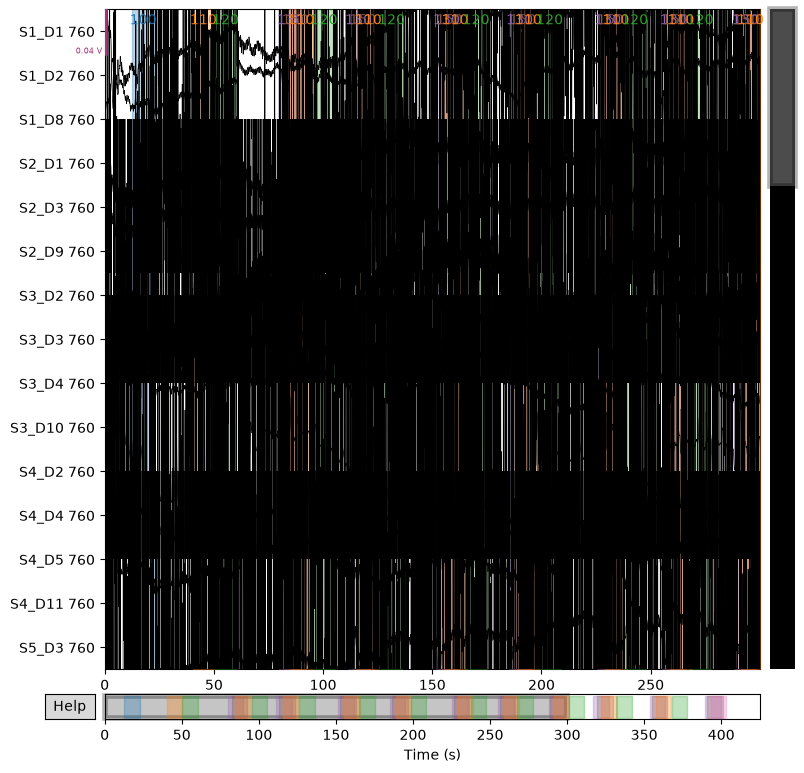


Conversão para densidade ótica concluída.
Objeto original: raw
Objeto em densidade ótica: raw_od
Ainda não foram aplicados SCI, TDDR, SSR ou filtragem.


In [4]:
# ============================================================
# 3. CONVERSÃO PARA DENSIDADE ÓTICA E INSPEÇÃO VISUAL
# ============================================================

# ------------------------------------------------------------
# 3.1 Converter intensidade ótica para densidade ótica
# ------------------------------------------------------------

print("A converter o sinal bruto para densidade ótica...")

raw_od = mne.preprocessing.nirs.optical_density(raw)


# ------------------------------------------------------------
# 3.2 Verificar o resultado da conversão
# ------------------------------------------------------------

tipos_od = raw_od.get_channel_types()

picks_od = np.array([
    indice
    for indice, tipo in enumerate(tipos_od)
    if tipo == "fnirs_od"
], dtype=int)

if len(picks_od) == 0:
    raise RuntimeError(
        "Não foram encontrados canais de densidade ótica "
        "após a conversão."
    )

dados_od = raw_od.get_data(picks=picks_od)

if not np.isfinite(dados_od).all():
    raise RuntimeError(
        "Foram encontrados valores NaN ou infinitos na densidade "
        "ótica. Interrompe o processamento e verifica o sinal."
    )

print("\n" + "=" * 70)
print("DENSIDADE ÓTICA")
print("=" * 70)

print(f"Séries de densidade ótica: {len(picks_od)}")
print(f"Número de amostras: {raw_od.n_times}")
print(f"Frequência de amostragem: {raw_od.info['sfreq']:.4f} Hz")
print(f"Valores finitos: {np.isfinite(dados_od).all()}")
print(f"Canais marcados como maus: {raw_od.info['bads']}")


# ------------------------------------------------------------
# 3.3 Visualizar a densidade ótica
# Não altera os dados usados nas etapas seguintes.
# ------------------------------------------------------------

mne.viz.set_browser_backend("matplotlib")

N_CANAIS_VISUALIZAR = min(15, len(picks_od))
DURACAO_VISUALIZAR_S = min(300.0, float(raw_od.times[-1]))

fig_od = raw_od.plot(
    picks=picks_od,
    n_channels=N_CANAIS_VISUALIZAR,
    start=0.0,
    duration=DURACAO_VISUALIZAR_S,
    title=f"{ID_GRAVACAO} — densidade ótica sem correção",
    show=True,
)

plt.show()


# ------------------------------------------------------------
# 3.4 Resumo da etapa
# ------------------------------------------------------------

print("\nConversão para densidade ótica concluída.")
print("Objeto original: raw")
print("Objeto em densidade ótica: raw_od")
print("Ainda não foram aplicados SCI, TDDR, SSR ou filtragem.")

A calcular o Scalp Coupling Index...

RESULTADOS DO SCI
Limiar: SCI < 0.7
Banda usada no cálculo: 0.7–1.5 Hz

Séries óticas marcadas como más: 18/56
Pares fonte–detetor marcados como maus: 9/28
Séries com SCI não finito: 0

Qualidade por par fonte–detetor:
par_fonte_detetor  n_series_oticas  sci_min  sci_max  sci_nao_finito  marcado_mau
            S1_D1                2 0.970253 0.970253           False        False
            S1_D2                2 0.979143 0.979143           False        False
            S1_D8                2 0.420712 0.420712           False         True
            S2_D1                2 0.886764 0.886764           False        False
            S2_D3                2 0.991481 0.991481           False        False
            S2_D9                2 0.074366 0.074366           False         True
            S3_D2                2 0.176640 0.176640           False         True
            S3_D3                2 0.983759 0.983759           False        False
     

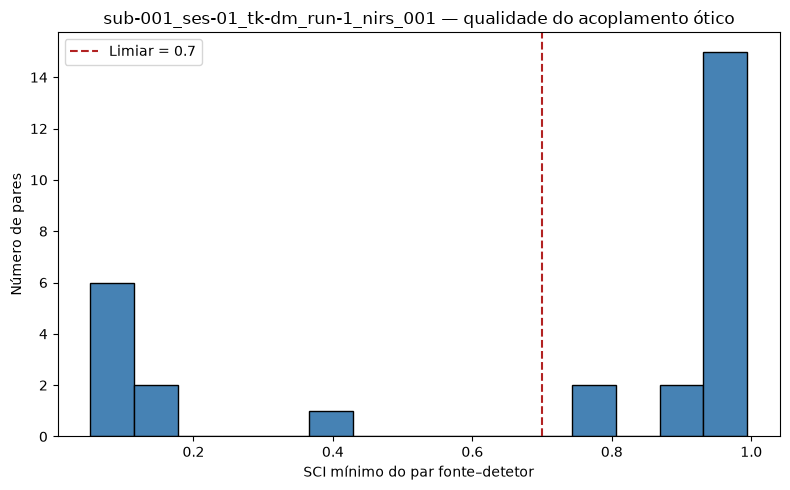


Ficheiros de controlo de qualidade guardados:
  sub-001_ses-01_tk-dm_run-1_nirs_001_sci_channels.csv
  sub-001_ses-01_tk-dm_run-1_nirs_001_sci_pairs.csv
  sub-001_ses-01_tk-dm_run-1_nirs_001_sci_histogram.png
  sub-001_ses-01_tk-dm_run-1_nirs_001_sci_parameters.json

SCI concluído.
Objeto para a etapa seguinte: raw_od_qc
Os canais maus foram marcados, mas não removidos.
Ainda não foram aplicados TDDR, SSR ou filtro hemodinâmico.


In [5]:
# ============================================================
# 4. CONTROLO DE QUALIDADE — SCALP COUPLING INDEX
# ============================================================

# ------------------------------------------------------------
# 4.1 Parâmetros
# ------------------------------------------------------------

LIMIAR_SCI = 0.7

SCI_LOW_HZ = 0.7
SCI_HIGH_HZ = 1.5


# ------------------------------------------------------------
# 4.2 Preparar uma cópia para controlo de qualidade
# raw_od permanece disponível antes da marcação desta etapa.
# ------------------------------------------------------------

raw_od_qc = raw_od.copy()

tipos_qc = raw_od_qc.get_channel_types()

if any(tipo != "fnirs_od" for tipo in tipos_qc):
    raise RuntimeError(
        "Este bloco espera apenas canais de densidade ótica. "
        "Foram encontrados outros tipos de canal; verifica "
        "a estrutura antes de calcular o SCI."
    )

bads_anteriores = list(raw_od_qc.info["bads"])


# ------------------------------------------------------------
# 4.3 Calcular o SCI sobre a gravação completa
# ------------------------------------------------------------

print("A calcular o Scalp Coupling Index...")

sci = mne.preprocessing.nirs.scalp_coupling_index(
    raw_od_qc,
    l_freq=SCI_LOW_HZ,
    h_freq=SCI_HIGH_HZ,
    verbose=False,
)

sci = np.asarray(sci, dtype=float)

if len(sci) != len(raw_od_qc.ch_names):
    raise RuntimeError(
        "O número de valores SCI não coincide com o número "
        "de séries óticas. Interrompe e verifica o resultado."
    )


# ------------------------------------------------------------
# 4.4 Construir a tabela de qualidade por série ótica
# Valores não finitos também são sinalizados.
# ------------------------------------------------------------

df_sci = pd.DataFrame({
    "canal": raw_od_qc.ch_names,
    "sci": sci,
})

df_sci["par_fonte_detetor"] = (
    df_sci["canal"].str.split().str[0]
)

df_sci["sci_nao_finito"] = ~np.isfinite(sci)
df_sci["sci_abaixo_limiar"] = sci < LIMIAR_SCI

df_sci["mau_previamente"] = (
    df_sci["canal"].isin(bads_anteriores)
)

df_sci["reprovado_sci"] = (
    df_sci["sci_nao_finito"]
    | df_sci["sci_abaixo_limiar"]
)


# ------------------------------------------------------------
# 4.5 Garantir marcação coerente por par fonte–detetor
# Se uma medição do par é reprovada, marca-se o par completo.
# Preserva também os canais anteriormente marcados.
# ------------------------------------------------------------

pares_maus = set(
    df_sci.loc[
        df_sci["reprovado_sci"] | df_sci["mau_previamente"],
        "par_fonte_detetor",
    ]
)

df_sci["marcado_mau_final"] = (
    df_sci["par_fonte_detetor"].isin(pares_maus)
)

bads_finais = df_sci.loc[
    df_sci["marcado_mau_final"],
    "canal",
].tolist()

raw_od_qc.info["bads"] = bads_finais


# ------------------------------------------------------------
# 4.6 Resumo por par fonte–detetor
# ------------------------------------------------------------

df_sci_pares = (
    df_sci
    .groupby("par_fonte_detetor", sort=False)
    .agg(
        n_series_oticas=("canal", "size"),
        sci_min=("sci", "min"),
        sci_max=("sci", "max"),
        sci_nao_finito=("sci_nao_finito", "any"),
        marcado_mau=("marcado_mau_final", "any"),
    )
    .reset_index()
)

n_series = len(df_sci)
n_series_maus = int(df_sci["marcado_mau_final"].sum())

n_pares = len(df_sci_pares)
n_pares_maus = int(df_sci_pares["marcado_mau"].sum())

print("\n" + "=" * 70)
print("RESULTADOS DO SCI")
print("=" * 70)

print(f"Limiar: SCI < {LIMIAR_SCI}")
print(f"Banda usada no cálculo: {SCI_LOW_HZ}–{SCI_HIGH_HZ} Hz")

print(
    f"\nSéries óticas marcadas como más: "
    f"{n_series_maus}/{n_series}"
)

print(
    f"Pares fonte–detetor marcados como maus: "
    f"{n_pares_maus}/{n_pares}"
)

print(
    "Séries com SCI não finito: "
    f"{int(df_sci['sci_nao_finito'].sum())}"
)

print("\nQualidade por par fonte–detetor:")
print(df_sci_pares.to_string(index=False))

if bads_finais:
    print("\nSéries marcadas como más:")
    for nome in bads_finais:
        print(f"  {nome}")
else:
    print("\nNenhuma série foi marcada como má.")


# ------------------------------------------------------------
# 4.7 Histograma — um valor por par fonte–detetor
# Evita contar duas vezes o mesmo par.
# ------------------------------------------------------------

valores_histograma = df_sci_pares.loc[
    ~df_sci_pares["sci_nao_finito"],
    "sci_min",
].to_numpy()

fig_sci, ax_sci = plt.subplots(figsize=(8, 5))

ax_sci.hist(
    valores_histograma,
    bins=15,
    edgecolor="black",
    color="steelblue",
)

ax_sci.axvline(
    LIMIAR_SCI,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label=f"Limiar = {LIMIAR_SCI}",
)

ax_sci.set(
    xlabel="SCI mínimo do par fonte–detetor",
    ylabel="Número de pares",
    title=f"{ID_GRAVACAO} — qualidade do acoplamento ótico",
)

ax_sci.legend()
fig_sci.tight_layout()


# ------------------------------------------------------------
# 4.8 Guardar resultados e parâmetros
# ------------------------------------------------------------

caminho_sci_series = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_sci_channels.csv"
)

caminho_sci_pares = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_sci_pairs.csv"
)

caminho_sci_figura = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_sci_histogram.png"
)

caminho_sci_parametros = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_sci_parameters.json"
)

df_sci.to_csv(
    caminho_sci_series,
    index=False,
    encoding="utf-8-sig",
)

df_sci_pares.to_csv(
    caminho_sci_pares,
    index=False,
    encoding="utf-8-sig",
)

fig_sci.savefig(
    caminho_sci_figura,
    dpi=300,
    bbox_inches="tight",
)

parametros_sci = {
    "id_gravacao": ID_GRAVACAO,
    "limiar_sci": LIMIAR_SCI,
    "l_freq_hz": SCI_LOW_HZ,
    "h_freq_hz": SCI_HIGH_HZ,
    "avaliacao": "gravacao_completa",
    "criterio": "SCI abaixo do limiar ou nao finito",
    "marcacao": "par fonte-detetor completo",
    "bads_anteriores": bads_anteriores,
    "bads_finais": bads_finais,
    "versoes": VERSOES,
}

with caminho_sci_parametros.open(
    "w",
    encoding="utf-8",
) as ficheiro:
    json.dump(
        parametros_sci,
        ficheiro,
        ensure_ascii=False,
        indent=2,
    )

plt.show()

print("\nFicheiros de controlo de qualidade guardados:")
for caminho in (
    caminho_sci_series,
    caminho_sci_pares,
    caminho_sci_figura,
    caminho_sci_parametros,
):
    print(f"  {caminho.name}")

print("\nSCI concluído.")
print("Objeto para a etapa seguinte: raw_od_qc")
print("Os canais maus foram marcados, mas não removidos.")
print("Ainda não foram aplicados TDDR, SSR ou filtro hemodinâmico.")

if n_pares_maus == n_pares:
    raise RuntimeError(
        "Todos os pares foram marcados como maus. "
        "Não avances para a correção de movimento antes "
        "de rever os resultados."
    )

A aplicar TDDR à densidade ótica...

VERIFICAÇÃO APÓS TDDR
Séries óticas totais: 56
Séries válidas após SCI: 38
Séries marcadas como más: 18
Número de amostras: 4323
Ordem dos canais preservada.
Marcação dos canais maus preservada.
Valores finitos nos canais válidos.


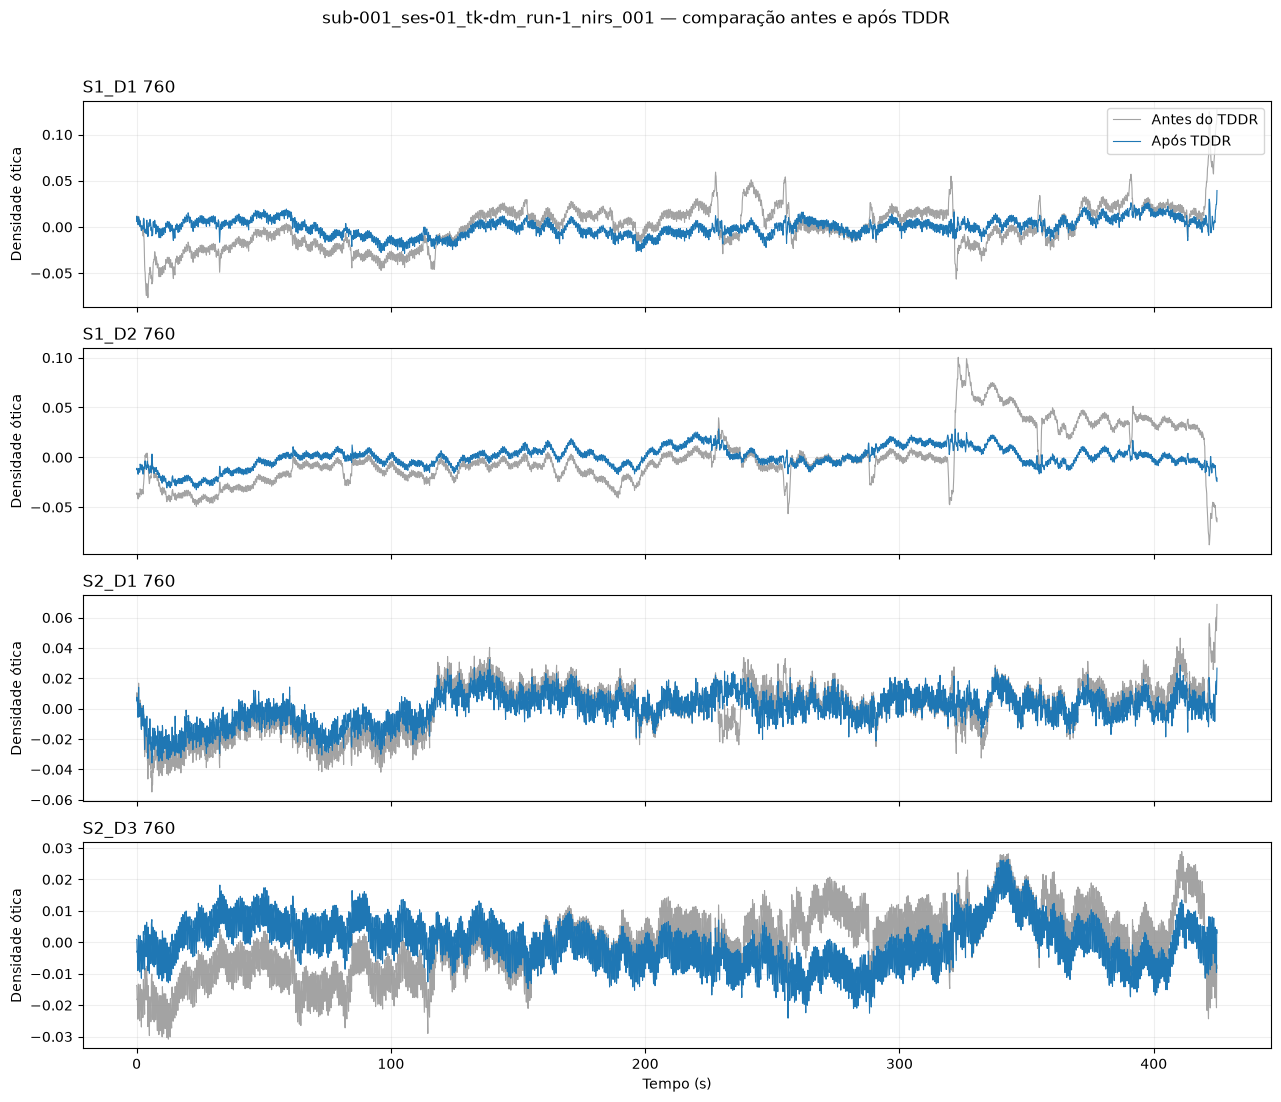


Ficheiros guardados:
  sub-001_ses-01_tk-dm_run-1_nirs_001_tddr_comparison.png
  sub-001_ses-01_tk-dm_run-1_nirs_001_tddr_parameters.json

TDDR concluído.
Objeto antes da correção: raw_od_qc
Objeto após a correção: raw_od_tddr
Os canais maus continuam marcados; não foram removidos.
Ainda não foram aplicados SSR ou filtro hemodinâmico.


In [6]:
# ============================================================
# 5. CORREÇÃO DE MOVIMENTO — TDDR
# ============================================================

# ------------------------------------------------------------
# 5.1 Verificar os dados de entrada
# ------------------------------------------------------------

if any(
    tipo != "fnirs_od"
    for tipo in raw_od_qc.get_channel_types()
):
    raise RuntimeError(
        "O TDDR desta pipeline deve receber o sinal "
        "em densidade ótica."
    )

bads_antes_tddr = list(raw_od_qc.info["bads"])

picks_validos_tddr = np.array([
    indice
    for indice, nome in enumerate(raw_od_qc.ch_names)
    if nome not in bads_antes_tddr
], dtype=int)

if len(picks_validos_tddr) == 0:
    raise RuntimeError(
        "Não existem canais válidos após o SCI. "
        "Revê o controlo de qualidade antes de continuar."
    )


# ------------------------------------------------------------
# 5.2 Aplicar TDDR
# A função devolve um objeto separado.
# ------------------------------------------------------------

print("A aplicar TDDR à densidade ótica...")

raw_od_tddr = (
    mne.preprocessing.nirs.temporal_derivative_distribution_repair(
        raw_od_qc,
        verbose=False,
    )
)


# ------------------------------------------------------------
# 5.3 Verificar a integridade do resultado
# ------------------------------------------------------------

if raw_od_tddr.ch_names != raw_od_qc.ch_names:
    raise RuntimeError(
        "A lista ou a ordem dos canais mudou durante o TDDR."
    )

if raw_od_tddr.n_times != raw_od_qc.n_times:
    raise RuntimeError(
        "O número de amostras mudou durante o TDDR."
    )

if set(raw_od_tddr.info["bads"]) != set(bads_antes_tddr):
    raise RuntimeError(
        "A marcação dos canais maus mudou durante o TDDR."
    )

if not np.isfinite(
    raw_od_tddr.get_data(picks=picks_validos_tddr)
).all():
    raise RuntimeError(
        "Foram encontrados valores NaN ou infinitos nos "
        "canais válidos após o TDDR."
    )

print("\n" + "=" * 70)
print("VERIFICAÇÃO APÓS TDDR")
print("=" * 70)

print(f"Séries óticas totais: {len(raw_od_tddr.ch_names)}")
print(f"Séries válidas após SCI: {len(picks_validos_tddr)}")
print(f"Séries marcadas como más: {len(bads_antes_tddr)}")
print(f"Número de amostras: {raw_od_tddr.n_times}")
print("Ordem dos canais preservada.")
print("Marcação dos canais maus preservada.")
print("Valores finitos nos canais válidos.")


# ------------------------------------------------------------
# 5.4 Comparação visual antes/depois
# Mostra os primeiros quatro canais válidos.
# Não altera os dados nem a marcação dos canais.
# ------------------------------------------------------------

N_CANAIS_COMPARAR = min(4, len(picks_validos_tddr))

picks_comparacao = picks_validos_tddr[:N_CANAIS_COMPARAR]

dados_antes = raw_od_qc.get_data(
    picks=picks_comparacao
)

dados_depois = raw_od_tddr.get_data(
    picks=picks_comparacao
)

tempos = raw_od_qc.times

fig_tddr, eixos_tddr = plt.subplots(
    nrows=N_CANAIS_COMPARAR,
    ncols=1,
    figsize=(13, 2.8 * N_CANAIS_COMPARAR),
    sharex=True,
    squeeze=False,
)

for linha, indice_canal in enumerate(picks_comparacao):
    ax = eixos_tddr[linha, 0]

    ax.plot(
        tempos,
        dados_antes[linha],
        color="0.55",
        linewidth=0.8,
        alpha=0.8,
        label="Antes do TDDR",
    )

    ax.plot(
        tempos,
        dados_depois[linha],
        color="tab:blue",
        linewidth=0.8,
        label="Após TDDR",
    )

    ax.set_title(
        raw_od_qc.ch_names[indice_canal],
        loc="left",
    )

    ax.set_ylabel("Densidade ótica")
    ax.grid(alpha=0.2)

eixos_tddr[0, 0].legend(loc="upper right")
eixos_tddr[-1, 0].set_xlabel("Tempo (s)")

fig_tddr.suptitle(
    f"{ID_GRAVACAO} — comparação antes e após TDDR",
    fontsize=12,
)

fig_tddr.tight_layout(rect=(0, 0, 1, 0.96))


# ------------------------------------------------------------
# 5.5 Guardar figura e parâmetros da etapa
# ------------------------------------------------------------

caminho_tddr_figura = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_tddr_comparison.png"
)

caminho_tddr_parametros = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_tddr_parameters.json"
)

fig_tddr.savefig(
    caminho_tddr_figura,
    dpi=300,
    bbox_inches="tight",
)

parametros_tddr = {
    "id_gravacao": ID_GRAVACAO,
    "metodo": "temporal_derivative_distribution_repair",
    "escala_entrada": "densidade_otica",
    "parametros_algoritmo": "predefinidos da implementacao MNE",
    "bads_preservados": bads_antes_tddr,
    "canais_comparacao_visual": [
        raw_od_qc.ch_names[indice]
        for indice in picks_comparacao
    ],
    "ssr_aplicada": False,
    "filtro_hemodinamico_aplicado": False,
    "versoes": VERSOES,
}

with caminho_tddr_parametros.open(
    "w",
    encoding="utf-8",
) as ficheiro:
    json.dump(
        parametros_tddr,
        ficheiro,
        ensure_ascii=False,
        indent=2,
    )

plt.show()

print("\nFicheiros guardados:")
print(f"  {caminho_tddr_figura.name}")
print(f"  {caminho_tddr_parametros.name}")

print("\nTDDR concluído.")
print("Objeto antes da correção: raw_od_qc")
print("Objeto após a correção: raw_od_tddr")
print("Os canais maus continuam marcados; não foram removidos.")
print("Ainda não foram aplicados SSR ou filtro hemodinâmico.")

In [7]:
# ============================================================
# 6. REGRESSÃO DE CANAIS CURTOS — SSR
# ============================================================

from mne_nirs.signal_enhancement import short_channel_regression


# ------------------------------------------------------------
# 6.1 Parâmetros e distâncias fonte–detetor
# ------------------------------------------------------------

DISTANCIA_MAX_CURTA_M = 0.01

distancias_m = mne.preprocessing.nirs.source_detector_distances(
    raw_od_tddr.info
)

if not np.isfinite(distancias_m).all():
    raise RuntimeError(
        "Existem distâncias fonte–detetor não finitas. "
        "Verifica a geometria antes de continuar."
    )

if np.any(distancias_m <= 0):
    raise RuntimeError(
        "Existem distâncias fonte–detetor nulas ou negativas. "
        "Verifica a geometria antes de continuar."
    )


# ------------------------------------------------------------
# 6.2 Tabela dos canais disponíveis para SSR
# ------------------------------------------------------------

df_ssr = pd.DataFrame({
    "canal": raw_od_tddr.ch_names,
    "distancia_m": distancias_m,
    "distancia_mm": distancias_m * 1000,
})

df_ssr["par_fonte_detetor"] = (
    df_ssr["canal"].str.split().str[0]
)

df_ssr["marcado_mau"] = df_ssr["canal"].isin(
    raw_od_tddr.info["bads"]
)

df_ssr["curto"] = (
    df_ssr["distancia_m"] < DISTANCIA_MAX_CURTA_M
)

df_ssr["valido"] = ~df_ssr["marcado_mau"]

df_ssr["curto_valido"] = (
    df_ssr["curto"] & df_ssr["valido"]
)

df_ssr["alvo_ssr"] = (
    (df_ssr["distancia_m"] > DISTANCIA_MAX_CURTA_M)
    & df_ssr["valido"]
)

canais_validos = df_ssr.loc[
    df_ssr["valido"], "canal"
].tolist()

canais_curtos_validos = df_ssr.loc[
    df_ssr["curto_valido"], "canal"
].tolist()

canais_alvo_ssr = df_ssr.loc[
    df_ssr["alvo_ssr"], "canal"
].tolist()

n_pares_curtos_validos = df_ssr.loc[
    df_ssr["curto_valido"], "par_fonte_detetor"
].nunique()

print("\n" + "=" * 70)
print("VIABILIDADE DA SSR")
print("=" * 70)

print(
    "Critério de canal curto: distância < "
    f"{DISTANCIA_MAX_CURTA_M * 1000:.1f} mm"
)

print(
    f"Séries óticas curtas válidas: "
    f"{len(canais_curtos_validos)}"
)

print(
    f"Pares fonte–detetor curtos válidos: "
    f"{n_pares_curtos_validos}"
)

print(
    f"Séries válidas candidatas à regressão: "
    f"{len(canais_alvo_ssr)}"
)

print("\nDistâncias e qualidade por série ótica:")
print(
    df_ssr[
        ["canal", "distancia_mm", "marcado_mau", "curto_valido"]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 6.3 Aplicar SSR quando viável
# A entrada da regressão contém apenas canais válidos.
# ------------------------------------------------------------

raw_od_ssr = raw_od_tddr.copy()

SSR_APLICADA = False
MOTIVO_SSR = ""

if len(canais_curtos_validos) == 0:
    MOTIVO_SSR = "Nenhum canal curto válido após o SCI."

elif len(canais_alvo_ssr) == 0:
    MOTIVO_SSR = "Nenhum canal válido acima do limite de distância."

else:
    dados_curtos = raw_od_tddr.get_data(
        picks=canais_curtos_validos
    )

    energia_curtos = np.sum(dados_curtos ** 2, axis=1)

    if (
        not np.isfinite(dados_curtos).all()
        or not np.isfinite(energia_curtos).all()
        or np.any(energia_curtos <= 0)
    ):
        raise RuntimeError(
            "Um ou mais canais curtos válidos apresentam "
            "valores inválidos ou energia nula. "
            "Revê estes canais antes de aplicar SSR."
        )

    print("\nA aplicar regressão de canais curtos...")

    entrada_ssr = raw_od_tddr.copy().pick(canais_validos)

    resultado_ssr = short_channel_regression(
        entrada_ssr,
        max_dist=DISTANCIA_MAX_CURTA_M,
    )

    dados_resultado = resultado_ssr.get_data()

    if not np.isfinite(dados_resultado).all():
        raise RuntimeError(
            "Foram encontrados valores não finitos após a SSR."
        )

    # Reintegrar as séries válidas na cópia completa.
    # Os canais maus permanecem presentes, marcados e inalterados.
    indices_destino = [
        raw_od_ssr.ch_names.index(nome)
        for nome in resultado_ssr.ch_names
    ]

    raw_od_ssr._data[indices_destino, :] = dados_resultado

    SSR_APLICADA = True
    MOTIVO_SSR = "SSR aplicada aos canais válidos elegíveis."


# ------------------------------------------------------------
# 6.4 Guardar auditoria da etapa
# ------------------------------------------------------------

df_ssr["regressao_aplicada"] = (
    df_ssr["alvo_ssr"] & SSR_APLICADA
)

caminho_ssr_tabela = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_ssr_channels.csv"
)

caminho_ssr_parametros = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_ssr_parameters.json"
)

df_ssr.to_csv(
    caminho_ssr_tabela,
    index=False,
    encoding="utf-8-sig",
)

parametros_ssr = {
    "id_gravacao": ID_GRAVACAO,
    "ssr_aplicada": SSR_APLICADA,
    "motivo": MOTIVO_SSR,
    "metodo": "mne_nirs.short_channel_regression",
    "distancia_max_curta_m": DISTANCIA_MAX_CURTA_M,
    "criterio_curto": "distancia < limite",
    "escala_entrada": "densidade_otica_apos_tddr",
    "canais_curtos_validos": canais_curtos_validos,
    "n_pares_curtos_validos": int(n_pares_curtos_validos),
    "canais_com_regressao": (
        canais_alvo_ssr if SSR_APLICADA else []
    ),
    "bads_preservados": list(raw_od_ssr.info["bads"]),
    "versoes": VERSOES,
}

with caminho_ssr_parametros.open(
    "w",
    encoding="utf-8",
) as ficheiro:
    json.dump(
        parametros_ssr,
        ficheiro,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 6.5 Resumo
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESULTADO DA ETAPA SSR")
print("=" * 70)

print(f"SSR aplicada: {SSR_APLICADA}")
print(f"Motivo: {MOTIVO_SSR}")

print("\nFicheiros guardados:")
print(f"  {caminho_ssr_tabela.name}")
print(f"  {caminho_ssr_parametros.name}")

print("\nObjeto para a etapa seguinte: raw_od_ssr")
print("Os canais maus continuam marcados e não foram removidos.")
print("Ainda não houve conversão para hemoglobina ou filtro hemodinâmico.")


VIABILIDADE DA SSR
Critério de canal curto: distância < 10.0 mm
Séries óticas curtas válidas: 0
Pares fonte–detetor curtos válidos: 0
Séries válidas candidatas à regressão: 38

Distâncias e qualidade por série ótica:
     canal  distancia_mm  marcado_mau  curto_valido
 S1_D1 760     30.590450        False         False
 S1_D2 760     30.479283        False         False
 S1_D8 760      8.701724         True         False
 S2_D1 760     35.957512        False         False
 S2_D3 760     30.398649        False         False
 S2_D9 760      8.158387         True         False
 S3_D2 760     45.582133         True         False
 S3_D3 760     31.593011        False         False
 S3_D4 760     39.104055        False         False
S3_D10 760      7.926195         True         False
 S4_D2 760     30.428150        False         False
 S4_D4 760     39.795237        False         False
 S4_D5 760     30.220428        False         False
S4_D11 760      7.618755         True         False
 S

In [8]:
# ============================================================
# 6.1 AUDITORIA DOS CANAIS CURTOS
# ============================================================

# ------------------------------------------------------------
# Juntar distâncias e resultados do SCI
# ------------------------------------------------------------

df_curtos_auditoria = (
    df_ssr.loc[
        df_ssr["curto"],
        [
            "canal",
            "par_fonte_detetor",
            "distancia_mm",
            "marcado_mau",
            "curto_valido",
        ],
    ]
    .merge(
        df_sci[
            [
                "canal",
                "sci",
                "sci_nao_finito",
                "sci_abaixo_limiar",
                "mau_previamente",
            ]
        ],
        on="canal",
        how="left",
        validate="one_to_one",
    )
)

print("=" * 70)
print("AUDITORIA DOS CANAIS CURTOS")
print("=" * 70)

print(f"Limiar SCI utilizado: {LIMIAR_SCI}")
print(
    "Critério de canal curto: distância < "
    f"{DISTANCIA_MAX_CURTA_M * 1000:.1f} mm"
)

if df_curtos_auditoria.empty:
    print("\nNão existem canais abaixo do limite de distância.")

else:
    with pd.option_context(
        "display.max_rows", None,
        "display.max_columns", None,
        "display.width", 180,
    ):
        print(
            df_curtos_auditoria.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.4f}",
            )
        )

    n_pares_curtos = (
        df_curtos_auditoria["par_fonte_detetor"].nunique()
    )

    n_pares_curtos_validos = (
        df_curtos_auditoria.loc[
            df_curtos_auditoria["curto_valido"],
            "par_fonte_detetor",
        ].nunique()
    )

    print(f"\nPares curtos existentes: {n_pares_curtos}")
    print(f"Pares curtos válidos: {n_pares_curtos_validos}")

print(f"\nSSR aplicada nesta run: {SSR_APLICADA}")
print(f"Motivo: {MOTIVO_SSR}")


# ------------------------------------------------------------
# Guardar tabela de auditoria
# ------------------------------------------------------------

caminho_curtos_auditoria = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_short_channels_audit.csv"
)

df_curtos_auditoria.to_csv(
    caminho_curtos_auditoria,
    index=False,
    encoding="utf-8-sig",
)

print(f"\nTabela guardada:\n{caminho_curtos_auditoria.name}")
print("\nNenhum parâmetro ou sinal foi alterado.")

AUDITORIA DOS CANAIS CURTOS
Limiar SCI utilizado: 0.7
Critério de canal curto: distância < 10.0 mm
     canal par_fonte_detetor  distancia_mm  marcado_mau  curto_valido    sci  sci_nao_finito  sci_abaixo_limiar  mau_previamente
 S1_D8 760             S1_D8        8.7017         True         False 0.4207           False               True            False
 S2_D9 760             S2_D9        8.1584         True         False 0.0744           False               True            False
S3_D10 760            S3_D10        7.9262         True         False 0.0850           False               True            False
S4_D11 760            S4_D11        7.6188         True         False 0.0523           False               True            False
S5_D12 760            S5_D12        7.0659         True         False 0.0905           False               True            False
S6_D13 760            S6_D13        7.3763         True         False 0.1088           False               True            Fals

In [9]:
# ============================================================
# 6.2 RESUMO DO ESTADO ATUAL
# ============================================================

print("=" * 70)
print("ESTADO ATUAL DA PIPELINE")
print("=" * 70)

print(f"Gravação: {ID_GRAVACAO}")
print("Conversão para densidade ótica: concluída")
print(f"Controlo de qualidade SCI: concluído, limiar = {LIMIAR_SCI}")
print("TDDR: concluído")
print(f"SSR aplicada: {SSR_APLICADA}")
print(f"Motivo: {MOTIVO_SSR}")

print("\nObjeto disponível para conversão em hemoglobina: raw_od_ssr")
print("Nesta run, esse objeto contém o sinal após TDDR, sem SSR.")

print("\nConversão para HbO/HbR: pendente")
print("Filtragem hemodinâmica: pendente")
print("Épocas e GLM: pendentes")

ESTADO ATUAL DA PIPELINE
Gravação: sub-001_ses-01_tk-dm_run-1_nirs_001
Conversão para densidade ótica: concluída
Controlo de qualidade SCI: concluído, limiar = 0.7
TDDR: concluído
SSR aplicada: False
Motivo: Nenhum canal curto válido após o SCI.

Objeto disponível para conversão em hemoglobina: raw_od_ssr
Nesta run, esse objeto contém o sinal após TDDR, sem SSR.

Conversão para HbO/HbR: pendente
Filtragem hemodinâmica: pendente
Épocas e GLM: pendentes


In [10]:
# ============================================================
# 7. CONVERSÃO PARA HEMOGLOBINA — HbO E HbR
# ============================================================

# ------------------------------------------------------------
# 7.1 Definir o PPF confirmado para esta validação
# ------------------------------------------------------------

PPF = 0.1


# ------------------------------------------------------------
# 7.2 Verificar a entrada e registar os pares marcados
# ------------------------------------------------------------

if any(
    tipo != "fnirs_od"
    for tipo in raw_od_ssr.get_channel_types()
):
    raise RuntimeError(
        "A conversão para hemoglobina exige dados "
        "em densidade ótica."
    )

pares_maus_antes_mbll = {
    nome.split()[0]
    for nome in raw_od_ssr.info["bads"]
}


# ------------------------------------------------------------
# 7.3 Aplicar a lei de Beer–Lambert modificada
# ------------------------------------------------------------

print(f"A converter para HbO e HbR com PPF = {PPF}...")

raw_haemo = mne.preprocessing.nirs.beer_lambert_law(
    raw_od_ssr,
    ppf=PPF,
)


# ------------------------------------------------------------
# 7.4 Verificar os cromóforos e a marcação dos canais maus
# ------------------------------------------------------------

tipos_haemo = raw_haemo.get_channel_types()

if any(tipo not in ("hbo", "hbr") for tipo in tipos_haemo):
    raise RuntimeError(
        "Foram encontrados tipos de canal inesperados "
        "após a conversão."
    )

pares_maus_apos_mbll = {
    nome.split()[0]
    for nome in raw_haemo.info["bads"]
}

if pares_maus_apos_mbll != pares_maus_antes_mbll:
    raise RuntimeError(
        "A identificação dos pares maus mudou durante "
        "a conversão. Verifica a marcação antes de continuar."
    )

df_haemo_canais = pd.DataFrame({
    "canal": raw_haemo.ch_names,
    "cromoforo": tipos_haemo,
})

df_haemo_canais["par_fonte_detetor"] = (
    df_haemo_canais["canal"].str.split().str[0]
)

df_haemo_canais["marcado_mau"] = (
    df_haemo_canais["canal"].isin(raw_haemo.info["bads"])
)

df_haemo_canais["distancia_mm"] = (
    mne.preprocessing.nirs.source_detector_distances(
        raw_haemo.info
    ) * 1000
)

picks_haemo_validos = np.flatnonzero(
    ~df_haemo_canais["marcado_mau"].to_numpy()
)

if len(picks_haemo_validos) == 0:
    raise RuntimeError(
        "Não existem séries hemodinâmicas válidas."
    )

if not np.isfinite(
    raw_haemo.get_data(picks=picks_haemo_validos)
).all():
    raise RuntimeError(
        "Existem valores NaN ou infinitos nos canais "
        "válidos após a conversão."
    )

if raw_haemo.n_times != raw_od_ssr.n_times:
    raise RuntimeError(
        "O número de amostras mudou durante a conversão."
    )

print("\n" + "=" * 70)
print("CONVERSÃO PARA HEMOGLOBINA")
print("=" * 70)

print(f"PPF utilizado: {PPF}")
print(f"SSR aplicada anteriormente: {SSR_APLICADA}")
print(f"Número de amostras: {raw_haemo.n_times}")

for cromoforo in ("hbo", "hbr"):
    selecao = df_haemo_canais["cromoforo"] == cromoforo

    total = int(selecao.sum())

    validos = int(
        (
            selecao
            & ~df_haemo_canais["marcado_mau"]
        ).sum()
    )

    print(
        f"{cromoforo.upper()}: "
        f"{total} séries totais; {validos} válidas"
    )

print("Marcação dos pares maus preservada.")
print("Valores finitos nos canais válidos.")


# ------------------------------------------------------------
# 7.5 Guardar o sinal convertido, a tabela e os parâmetros
# ------------------------------------------------------------

caminho_haemo_raw = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_haemo_unfiltered_raw.fif"
)

caminho_haemo_canais = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_haemo_channels.csv"
)

caminho_mbll_parametros = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_mbll_parameters.json"
)

raw_haemo.save(
    caminho_haemo_raw,
    overwrite=True,
    verbose=False,
)

df_haemo_canais.to_csv(
    caminho_haemo_canais,
    index=False,
    encoding="utf-8-sig",
)

parametros_mbll = {
    "id_gravacao": ID_GRAVACAO,
    "metodo": "modified_beer_lambert_law",
    "ppf": PPF,
    "cromoforos": ["hbo", "hbr"],
    "tddr_aplicado": True,
    "ssr_aplicada": SSR_APLICADA,
    "motivo_ssr": MOTIVO_SSR,
    "filtro_hemodinamico_aplicado": False,
    "selecao_final_canais_longos": False,
    "bads": list(raw_haemo.info["bads"]),
    "versoes": VERSOES,
}

with caminho_mbll_parametros.open(
    "w",
    encoding="utf-8",
) as ficheiro:
    json.dump(
        parametros_mbll,
        ficheiro,
        ensure_ascii=False,
        indent=2,
    )

print("\nFicheiros guardados:")
print(f"  {caminho_haemo_raw.name}")
print(f"  {caminho_haemo_canais.name}")
print(f"  {caminho_mbll_parametros.name}")

print("\nConversão para HbO e HbR concluída.")
print("Objeto para a etapa seguinte: raw_haemo")
print("Os canais maus continuam marcados e não foram removidos.")
print("O filtro hemodinâmico ainda não foi aplicado.")

A converter para HbO e HbR com PPF = 0.1...

CONVERSÃO PARA HEMOGLOBINA
PPF utilizado: 0.1
SSR aplicada anteriormente: False
Número de amostras: 4323
HBO: 28 séries totais; 19 válidas
HBR: 28 séries totais; 19 válidas
Marcação dos pares maus preservada.
Valores finitos nos canais válidos.

Ficheiros guardados:
  sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_unfiltered_raw.fif
  sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_channels.csv
  sub-001_ses-01_tk-dm_run-1_nirs_001_mbll_parameters.json

Conversão para HbO e HbR concluída.
Objeto para a etapa seguinte: raw_haemo
Os canais maus continuam marcados e não foram removidos.
O filtro hemodinâmico ainda não foi aplicado.


A aplicar filtro passa-banda 0.01–0.50 Hz...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.5 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 16 (effective, after forward-backward)
- Cutoffs at 0.01, 0.50 Hz: -6.02, -6.02 dB



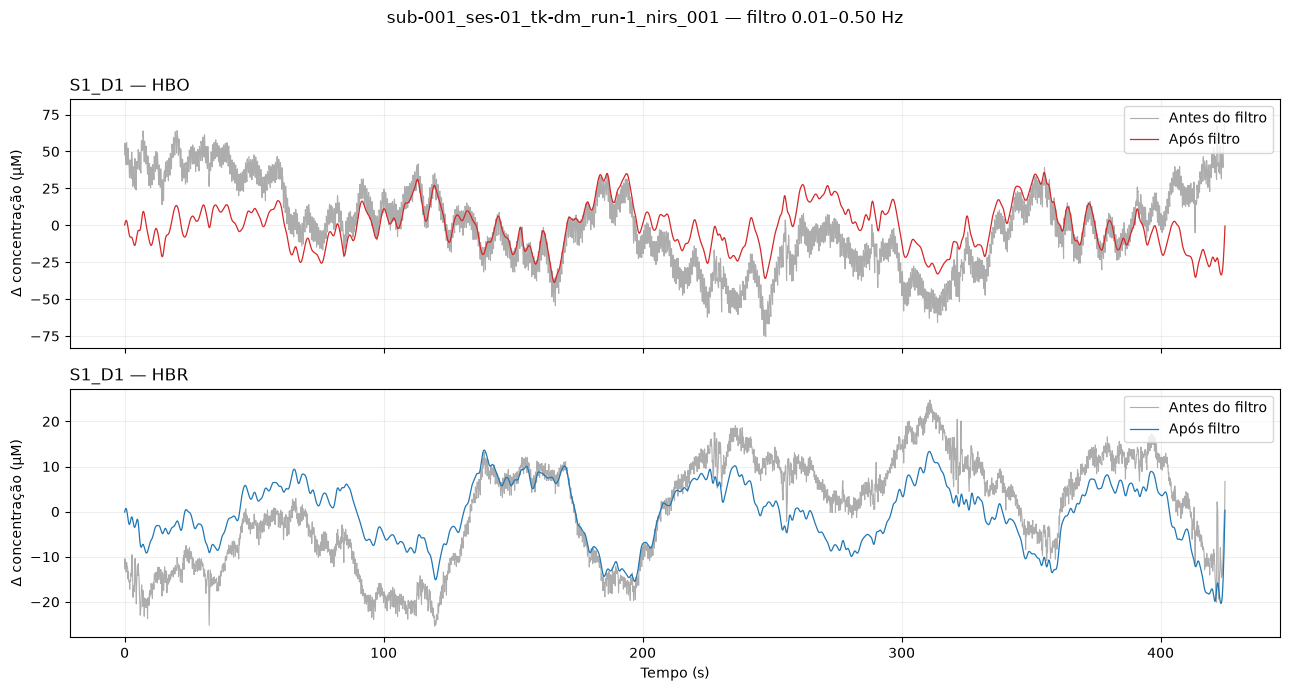


FILTRAGEM CONCLUÍDA
Passa-banda: 0.01–0.5 Hz
Método: iir
Parâmetros IIR: {'order': 4, 'ftype': 'butter', 'output': 'sos'}
Fase: zero
Séries válidas: 38
Marcação dos canais maus preservada.
Valores finitos nos canais válidos.

Ficheiros guardados:
  sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_filtered_raw.fif
  sub-001_ses-01_tk-dm_run-1_nirs_001_filter_comparison.png
  sub-001_ses-01_tk-dm_run-1_nirs_001_filter_parameters.json

Objeto antes da filtragem: raw_haemo
Objeto após a filtragem: raw_filtrado
Ainda não foram criadas épocas nem ajustado o GLM.


In [11]:
# ============================================================
# 8. FILTRAGEM TEMPORAL — HbO E HbR
# ============================================================

# ------------------------------------------------------------
# 8.1 Parâmetros do filtro
# ------------------------------------------------------------

LOW_CUTOFF_HZ = 0.01
HIGH_CUTOFF_HZ = 0.50

METODO_FILTRO = "iir"
FASE_FILTRO = "zero"

IIR_PARAMS = {
    "order": 4,
    "ftype": "butter",
    "output": "sos",
}


# ------------------------------------------------------------
# 8.2 Verificar os dados de entrada
# ------------------------------------------------------------

tipos_entrada = raw_haemo.get_channel_types()

if any(tipo not in ("hbo", "hbr") for tipo in tipos_entrada):
    raise RuntimeError(
        "Este bloco espera apenas canais de HbO e HbR."
    )

nyquist_hz = raw_haemo.info["sfreq"] / 2

if not 0 < LOW_CUTOFF_HZ < HIGH_CUTOFF_HZ < nyquist_hz:
    raise ValueError(
        "Os limites do filtro são incompatíveis com "
        "a frequência de amostragem."
    )

bads_antes_filtro = list(raw_haemo.info["bads"])

picks_todos_haemo = np.arange(
    len(raw_haemo.ch_names),
    dtype=int,
)

picks_validos_filtro = np.array([
    indice
    for indice, nome in enumerate(raw_haemo.ch_names)
    if nome not in bads_antes_filtro
], dtype=int)

if len(picks_validos_filtro) == 0:
    raise RuntimeError(
        "Não existem canais válidos para continuar."
    )


# ------------------------------------------------------------
# 8.3 Aplicar o filtro numa cópia
# A seleção explícita inclui os canais marcados como maus.
# A sua marcação permanece inalterada.
# ------------------------------------------------------------

print(
    "A aplicar filtro passa-banda "
    f"{LOW_CUTOFF_HZ:.2f}–{HIGH_CUTOFF_HZ:.2f} Hz..."
)

raw_filtrado = raw_haemo.copy().filter(
    l_freq=LOW_CUTOFF_HZ,
    h_freq=HIGH_CUTOFF_HZ,
    picks=picks_todos_haemo,
    method=METODO_FILTRO,
    iir_params=IIR_PARAMS.copy(),
    phase=FASE_FILTRO,
    verbose=True,
)


# ------------------------------------------------------------
# 8.4 Verificar o resultado
# ------------------------------------------------------------

if raw_filtrado.ch_names != raw_haemo.ch_names:
    raise RuntimeError(
        "A lista ou ordem dos canais mudou durante a filtragem."
    )

if raw_filtrado.n_times != raw_haemo.n_times:
    raise RuntimeError(
        "O número de amostras mudou durante a filtragem."
    )

if set(raw_filtrado.info["bads"]) != set(bads_antes_filtro):
    raise RuntimeError(
        "A marcação dos canais maus mudou durante a filtragem."
    )

if not np.isfinite(
    raw_filtrado.get_data(picks=picks_validos_filtro)
).all():
    raise RuntimeError(
        "Existem valores NaN ou infinitos nos canais "
        "válidos após a filtragem."
    )


# ------------------------------------------------------------
# 8.5 Comparação visual antes/depois
# Primeiro par válido com ambos os cromóforos.
# A multiplicação por 1e6 é apenas para apresentar em µM.
# ------------------------------------------------------------

pares_validos = {}

for indice in picks_validos_filtro:
    nome = raw_haemo.ch_names[indice]
    par = nome.split()[0]
    cromoforo = tipos_entrada[indice]

    pares_validos.setdefault(par, {})[cromoforo] = int(indice)

par_visualizacao = next(
    (
        par
        for par, canais in pares_validos.items()
        if "hbo" in canais and "hbr" in canais
    ),
    None,
)

if par_visualizacao is None:
    raise RuntimeError(
        "Não foi encontrado um par válido com HbO e HbR."
    )

fig_filtro, eixos_filtro = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(13, 7),
    sharex=True,
)

for ax, cromoforo in zip(eixos_filtro, ("hbo", "hbr")):
    indice = pares_validos[par_visualizacao][cromoforo]

    antes = raw_haemo.get_data(picks=[indice])[0] * 1e6
    depois = raw_filtrado.get_data(picks=[indice])[0] * 1e6

    ax.plot(
        raw_haemo.times,
        antes,
        color="0.6",
        linewidth=0.8,
        alpha=0.8,
        label="Antes do filtro",
    )

    ax.plot(
        raw_filtrado.times,
        depois,
        color="tab:red" if cromoforo == "hbo" else "tab:blue",
        linewidth=0.9,
        label="Após filtro",
    )

    ax.set_title(
        f"{par_visualizacao} — {cromoforo.upper()}",
        loc="left",
    )

    ax.set_ylabel("Δ concentração (µM)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.2)

eixos_filtro[-1].set_xlabel("Tempo (s)")

fig_filtro.suptitle(
    f"{ID_GRAVACAO} — filtro "
    f"{LOW_CUTOFF_HZ:.2f}–{HIGH_CUTOFF_HZ:.2f} Hz"
)

fig_filtro.tight_layout(rect=(0, 0, 1, 0.95))


# ------------------------------------------------------------
# 8.6 Guardar sinal, figura e parâmetros
# ------------------------------------------------------------

caminho_filtrado_raw = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_haemo_filtered_raw.fif"
)

caminho_filtro_figura = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_filter_comparison.png"
)

caminho_filtro_parametros = (
    PASTA_DERIVATIVES
    / f"{ID_GRAVACAO}_filter_parameters.json"
)

raw_filtrado.save(
    caminho_filtrado_raw,
    overwrite=True,
    verbose=False,
)

fig_filtro.savefig(
    caminho_filtro_figura,
    dpi=300,
    bbox_inches="tight",
)

parametros_filtro = {
    "id_gravacao": ID_GRAVACAO,
    "l_freq_hz": LOW_CUTOFF_HZ,
    "h_freq_hz": HIGH_CUTOFF_HZ,
    "metodo": METODO_FILTRO,
    "phase": FASE_FILTRO,
    "iir_params": IIR_PARAMS,
    "canais_filtrados": "todos os canais HbO e HbR",
    "ppf": PPF,
    "ssr_aplicada": SSR_APLICADA,
    "bads_preservados": bads_antes_filtro,
    "par_comparacao_visual": par_visualizacao,
    "selecao_final_canais_longos": False,
    "versoes": VERSOES,
}

with caminho_filtro_parametros.open(
    "w",
    encoding="utf-8",
) as ficheiro:
    json.dump(
        parametros_filtro,
        ficheiro,
        ensure_ascii=False,
        indent=2,
    )

plt.show()

print("\n" + "=" * 70)
print("FILTRAGEM CONCLUÍDA")
print("=" * 70)

print(f"Passa-banda: {LOW_CUTOFF_HZ}–{HIGH_CUTOFF_HZ} Hz")
print(f"Método: {METODO_FILTRO}")
print(f"Parâmetros IIR: {IIR_PARAMS}")
print(f"Fase: {FASE_FILTRO}")
print(f"Séries válidas: {len(picks_validos_filtro)}")
print("Marcação dos canais maus preservada.")
print("Valores finitos nos canais válidos.")

print("\nFicheiros guardados:")
print(f"  {caminho_filtrado_raw.name}")
print(f"  {caminho_filtro_figura.name}")
print(f"  {caminho_filtro_parametros.name}")

print("\nObjeto antes da filtragem: raw_haemo")
print("Objeto após a filtragem: raw_filtrado")
print("Ainda não foram criadas épocas nem ajustado o GLM.")